# Детекция объектов: Faster R-CNN на датасете Fashionpedia

**Задача.** Познакомиться с современными детекторами объектов, применить предобученную модель к набору изображений, дообучить её на собственном датасете из 5–10 классов, оценить качество через mAP при разных порогах IoU и показать предсказания на тестовых картинках.

**Подход.** Two-stage детектор **Faster R-CNN** ([Ren et al., 2015](https://arxiv.org/abs/1506.01497)) с backbone ResNet-50 и FPN из `torchvision`, предобученный на COCO. Дообучается на [Fashionpedia](https://huggingface.co/datasets/detection-datasets/fashionpedia): предметы одежды на фотографиях людей, 10 классов. Ни одного из них нет в COCO, поэтому хорошо видно, что даёт дообучение.

**Содержание.** 1 Настройка · 2 Обзор модели · 3 Датасет · 4 Модель до дообучения · 5 Дообучение · 6 Оценка: mAP при разных IoU · 7 Предсказания до и после · 8 Разбор ошибок и контрольные вопросы · 9 Выводы


## 1. Настройка

In [ ]:
import csv
import io
import itertools
import json
import platform
import random
import sys
import time
import warnings
from collections import Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from contextlib import redirect_stdout
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.optim import SGD
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from tqdm import tqdm as _tqdm

warnings.filterwarnings("ignore", category=UserWarning)


def tqdm(*args, **kwargs):
    return _tqdm(*args, file=sys.stdout, mininterval=1.0, dynamic_ncols=True, **kwargs)

In [ ]:
# True — быстрая проверка пайплайна, False — полное обучение
SMOKE = False

TASK_DIR = Path.cwd()
assert (TASK_DIR / "fashion_frcnn.ipynb").exists(), "Ноутбук нужно запускать из папки task-1-1-detection-a"
DATA = TASK_DIR / "data" / ("smoke" if SMOKE else "prepared")          # подготовленная выборка: картинки + разметка
RESULTS = TASK_DIR / "results" / "smoke" if SMOKE else TASK_DIR / "results"   # метрики, графики, примеры
CKPT = TASK_DIR / "checkpoints" / ("smoke" if SMOKE else "")            # чекпоинты и лучшие веса (в git не попадают)

SEED = 42
HF_DATASET = "detection-datasets/fashionpedia"

# Наши классы → категории Fashionpedia, которые в них объединяются
CLASSES = {
    "top": ["top, t-shirt, sweatshirt"],
    "shirt": ["shirt, blouse"],
    "outerwear": ["jacket", "coat"],
    "knitwear": ["sweater", "cardigan"],
    "pants": ["pants"],
    "shorts": ["shorts"],
    "skirt": ["skirt"],
    "dress": ["dress"],
    "shoe": ["shoe"],
    "bag": ["bag, wallet"],
}
CLASS_NAMES = ["__background__", *CLASSES]   # индекс 0 в torchvision зарезервирован под фон
NUM_CLASSES = len(CLASS_NAMES)

DATA_CFG = dict(train=6000, val=600, test=None, max_side=1024, threads=8)
TRAIN_CFG = dict(name="frcnn_fashion", epochs=10, batch_size=4, lr=0.005, momentum=0.9, weight_decay=1e-4,
                 warmup_iters=500, lr_drop_epochs=[7, 9], min_size=640, max_size=1024,
                 trainable_backbone_layers=3, loader_threads=6, log_every=50, max_iters_per_epoch=None)
if SMOKE:
    DATA_CFG.update(train=24, val=8, test=8)
    TRAIN_CFG.update(epochs=2, batch_size=2, warmup_iters=4, lr_drop_epochs=[2], min_size=320, max_size=512,
                     log_every=2, max_iters_per_epoch=6)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def env_info():
    info = {"python": sys.version.split()[0], "platform": platform.platform(), "torch": torch.__version__,
            "cuda_available": torch.cuda.is_available()}
    if torch.cuda.is_available():
        info.update(cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0), arch_list=torch.cuda.get_arch_list())
    return info


def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=1), encoding="utf-8")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"   
torch.backends.cudnn.benchmark = True
seed_everything(SEED)
if device.type != "cuda":
    print("ВНИМАНИЕ: CUDA недоступна, всё пойдёт на CPU и будет очень медленно.")
print(json.dumps(env_info(), ensure_ascii=False, indent=1))

{
 "python": "3.12.0",
 "platform": "Windows-10-10.0.19045-SP0",
 "torch": "2.11.0+cu128",
 "cuda_available": true,
 "cuda": "12.8",
 "gpu": "NVIDIA GeForce RTX 5060",
 "arch_list": [
  "sm_75",
  "sm_80",
  "sm_86",
  "sm_90",
  "sm_100",
  "sm_120"
 ]
}


In [ ]:
# ---------- Картинки (numpy, RGB, uint8, H×W×3) и отрисовка рамок ----------
def decode_rgb(buf):
    img = cv2.imdecode(np.frombuffer(buf, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("не удалось декодировать изображение")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def imread_rgb(path):
    return decode_rgb(np.fromfile(str(path), np.uint8))


def imwrite_rgb(path, img, quality=92):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, quality])
    if not ok:
        raise ValueError(f"не удалось закодировать {path}")
    buf.tofile(str(path))


def to_tensor(img):
    return torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float().div_(255)


PALETTE = plt.get_cmap("tab20").colors


def draw_boxes(ax, img, boxes, labels, names, scores=None, title=None):
    # Рамки подписываются именем класса и, если есть, уверенностью модели
    ax.imshow(img)
    for i, (box, label) in enumerate(zip(boxes, labels)):
        x1, y1, x2, y2 = box
        color = PALETTE[int(label) % len(PALETTE)]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.6))
        text = names[int(label)] + (f" {scores[i]:.2f}" if scores is not None else "")
        ax.text(x1 + 2, y1 + 2, text, fontsize=7, color="white", va="top",
                bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=9)


def show_grid(columns, titles, path=None, width=4.2):
    # columns: список столбцов, каждый столбец — список (img, boxes, labels, names, scores)
    rows = len(columns[0])
    fig, axes = plt.subplots(rows, len(columns), figsize=(width * len(columns), width * 0.95 * rows), squeeze=False)
    for c, column in enumerate(columns):
        for r, item in enumerate(column):
            draw_boxes(axes[r][c], *item, title=titles[c] if r == 0 else None)
    fig.tight_layout()
    if path:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=110)
    plt.show()

## 2. Краткий обзор модели

**Детекция объектов** отличается от классификации тем, что ответ - не одна метка на картинку, а список объектов, у каждого из которых прямоугольная рамка (bounding box), класс и уверенность. От сегментации детекция отличается грубостью: вместо маски по пикселям только рамка.

**Faster R-CNN** - two-stage детектор. Картинка проходит через четыре блока:

1. **Backbone + FPN.** ResNet-50 извлекает признаки; Feature Pyramid Network объединяет карты признаков разных масштабов, чтобы мелкие и крупные объекты искались на подходящем уровне пирамиды.
2. **RPN (Region Proposal Network).** Для якорей (anchors) разных размеров и пропорций в каждой точке карты признаков предсказывает, есть ли там объект, и уточняет рамку. На выходе - около 1000 кандидатов (proposals) без класса.
3. **RoIAlign.** Из карты признаков вырезаются области под каждый кандидат и приводятся к фиксированному размеру 7×7.
4. **Голова детекции.** Два полносвязных слоя, затем классификация кандидата (K классов + фон) и регрессия точных координат рамки. Дубликаты убираются NMS.

Именно голова заменяется при дообучении: её последний слой рассчитан на 91 класс COCO, а нам нужно 10 + фон. Остальные веса сохраняются и дообучаются с меньшим темпом.

В `torchvision` используется вариант **Faster R-CNN ResNet-50 FPN v2** ([Li et al., 2021](https://arxiv.org/abs/2111.11429)): больше свёрток в головах RPN и детекции, mAP на COCO 46,7 против 37,0 у первой версии.

**One-stage детекторы** (YOLO, SSD) пропускают этап кандидатов: сетка якорей сразу даёт класс и рамку за один проход. Подробное сравнение — в разделе 8.

**Метрики.**
- **IoU** (Intersection over Union) - площадь пересечения рамок, делённая на площадь объединения. Детекция считается верной, если IoU с настоящей рамкой не ниже порога и класс совпадает.
- **AP** (Average Precision) - площадь под кривой precision-recall для одного класса при заданном пороге IoU. **mAP** — среднее AP по классам. В COCO стандарт — среднее mAP по десяти порогам IoU от 0,50 до 0,95 с шагом 0,05; отдельно смотрят mAP@0.5 (мягкий порог, VOC-стиль) и mAP@0.75 (строгий).

## 3. Датасет Fashionpedia

**[Fashionpedia](https://fashionpedia.github.io/home/)** (CVPR 2020) - 46 781 фотография людей в одежде с разметкой экспертов-модельеров: 27 категорий предметов одежды, 19 категорий деталей (воротник, рукав, карман) и атрибуты. Лицензия CC BY 4.0, на HuggingFace лежит версия с рамками в формате для детекции.

**Выбор классов.** Берём 10 цельных предметов, детали вроде рукавов и карманов в разметку не попадают и считаются фоном. Близкие категории объединены, чтобы не заставлять модель различать «куртку» и «пальто» по рамке:

| Класс | Категории Fashionpedia |
|---|---|
| top | top, t-shirt, sweatshirt |
| shirt | shirt, blouse |
| outerwear | jacket; coat |
| knitwear | sweater; cardigan |
| pants | pants |
| shorts | shorts |
| skirt | skirt |
| dress | dress |
| shoe | shoe |
| bag | bag, wallet |

**Разбиение.** Из официального train случайно берутся 6000 картинок на обучение и 600 на валидацию (только картинки, где есть хотя бы один объект наших классов). Официальный val (1158 картинок) целиком служит тестом: модель видит его один раз, в разделе 6. Картинки уменьшаются до 1024 px по длинной стороне и сохраняются в `data/prepared/`, разметка в своём JSON: `boxes` в пикселях `[x1, y1, x2, y2]`, `labels` - индексы в `CLASS_NAMES`.

В режиме `SMOKE` датасет читается потоком с HuggingFace: нужные несколько десятков картинок, а не весь архив.

data/train-00000-of-00007-fe108070118553(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00000-of-00007-fe108070118553(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f41a5a9c38c900(…): reconstructing file:   0%|          |  0.00B /  480MB            

data/train-00001-of-00007-f41a5a9c38c900(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-40bc8456894bcb(…): reconstructing file:   0%|          |  0.00B /  480MB            

data/train-00002-of-00007-40bc8456894bcb(…): downloading bytes:           |  0.00B            

... (10 outputs left out)

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

train+val: 100%|██████████| 6600/6600 [00:07<00:00, 908.94it/s]
test: 1155it [00:01, 847.57it/s]


| Класс | train (6000 карт.) | val (600 карт.) | test (1155 карт.) |
|---|---|---|---|
| top | 2233 | 235 | 477 |
| shirt | 839 | 74 | 102 |
| outerwear | 1443 | 144 | 287 |
| knitwear | 333 | 28 | 33 |
| pants | 1624 | 152 | 314 |
| shorts | 388 | 36 | 106 |
| skirt | 696 | 76 | 162 |
| dress | 2454 | 240 | 508 |
| shoe | 6106 | 548 | 1566 |
| bag | 969 | 102 | 214 |


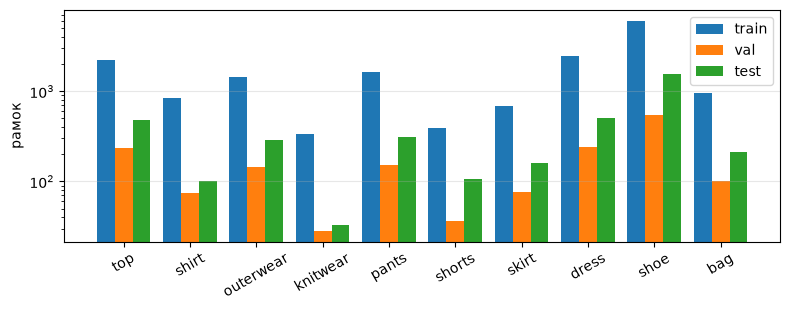

In [15]:
CAT_TO_LABEL = {cat: i for i, (name, cats) in enumerate(CLASSES.items(), start=1) for cat in cats}


def hf_split(split, shuffle):
    # Image(decode=False) отдаёт байты JPEG без декодирования: декодируем сами через cv2 только нужные картинки
    from datasets import Image, load_dataset
    ds = load_dataset(HF_DATASET, split=split, streaming=SMOKE)
    ds = ds.cast_column("image", Image(decode=False))
    if shuffle:
        ds = ds.shuffle(seed=SEED, buffer_size=256) if SMOKE else ds.shuffle(seed=SEED)
    cats = ds.features["objects"]["category"].feature.names
    return ds, cats


def convert_row(row, cats, out_dir, max_side):
    # → запись о картинке или None, если на ней нет объектов наших классов
    boxes, labels = [], []
    for cat_id, box in zip(row["objects"]["category"], row["objects"]["bbox"]):
        label = CAT_TO_LABEL.get(cats[cat_id])
        if label:
            boxes.append([float(v) for v in box])
            labels.append(label)
    if not boxes:
        return None
    img = decode_rgb(row["image"]["bytes"])
    h, w = img.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        img = cv2.resize(img, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
        boxes = [[v * scale for v in b] for b in boxes]
    h, w = img.shape[:2]
    boxes = [[max(0.0, b[0]), max(0.0, b[1]), min(float(w), b[2]), min(float(h), b[3])] for b in boxes]
    keep = [i for i, b in enumerate(boxes) if b[2] - b[0] >= 2 and b[3] - b[1] >= 2]
    if not keep:
        return None
    file = (out_dir.relative_to(DATA) / "images" / f"{row['image_id']}.jpg").as_posix()   # путь относительно DATA
    imwrite_rgb(DATA / file, img)
    return {"id": int(row["image_id"]), "file": file, "width": w, "height": h,
            "boxes": [boxes[i] for i in keep], "labels": [labels[i] for i in keep]}


def collect(ds, cats, out_dir, limit, threads, desc):
    # Поток строк → пул потоков на декодирование/resize/запись; cv2 отпускает GIL, так что потоки работают параллельно
    records, pool, pending = [], ThreadPoolExecutor(threads), deque()
    pbar = tqdm(total=limit, desc=desc)
    try:
        for row in ds:
            pending.append(pool.submit(convert_row, row, cats, out_dir, DATA_CFG["max_side"]))
            while pending and (pending[0].done() or len(pending) >= threads * 2):
                rec = pending.popleft().result()
                if rec:
                    records.append(rec)
                    pbar.update(1)
            if limit and len(records) >= limit:
                break
        for f in pending:
            rec = f.result()
            if rec and (not limit or len(records) < limit):
                records.append(rec)
                pbar.update(1)
    finally:
        pbar.close()
        pool.shutdown(wait=False, cancel_futures=True)
    return records[:limit] if limit else records


def prepare_data():
    if (DATA / "test.json").exists():
        print(f"Данные уже подготовлены в {DATA}")
        return
    if SMOKE:
        # Всё из небольшого официального val (85 МБ) потоком: train / val / test — последовательные куски
        ds, cats = hf_split("val", shuffle=False)
        n_train, n_val = DATA_CFG["train"], DATA_CFG["val"]
        records = collect(ds, cats, DATA / "smoke", n_train + n_val + DATA_CFG["test"], DATA_CFG["threads"], "smoke")
        write_json(DATA / "train.json", records[:n_train])
        write_json(DATA / "val.json", records[n_train:n_train + n_val])
        write_json(DATA / "test.json", records[n_train + n_val:])
        return
    ds, cats = hf_split("train", shuffle=True)
    want = DATA_CFG["train"] + DATA_CFG["val"]
    records = collect(ds, cats, DATA / "trainval", want, DATA_CFG["threads"], "train+val")
    assert len(records) == want, f"собрано {len(records)} картинок из {want}"
    write_json(DATA / "train.json", records[: DATA_CFG["train"]])
    write_json(DATA / "val.json", records[DATA_CFG["train"]:])
    ds, cats = hf_split("val", shuffle=False)
    write_json(DATA / "test.json", collect(ds, cats, DATA / "test", DATA_CFG["test"], DATA_CFG["threads"], "test"))


def load_split(split):
    records = read_json(DATA / f"{split}.json")
    for r in records:
        r["path"] = DATA / r["file"]
    return records


def dataset_summary(splits):
    rows = {name: Counter(CLASS_NAMES[l] for r in recs for l in r["labels"]) for name, recs in splits.items()}
    table = "| Класс | " + " | ".join(f"{s} ({len(r)} карт.)" for s, r in splits.items()) + " |\n|---|" + "---|" * len(splits) + "\n"
    for name in CLASS_NAMES[1:]:
        table += f"| {name} | " + " | ".join(str(rows[s][name]) for s in splits) + " |\n"
    display(Markdown(table))
    write_json(RESULTS / "dataset_summary.json", {s: {"images": len(r), "boxes": dict(rows[s])} for s, r in splits.items()})
    fig, ax = plt.subplots(figsize=(8, 3.2))
    x = np.arange(NUM_CLASSES - 1)
    for i, s in enumerate(splits):
        ax.bar(x + (i - 1) * 0.27, [rows[s][n] for n in CLASS_NAMES[1:]], width=0.27, label=s)
    ax.set_xticks(x, CLASS_NAMES[1:], rotation=30)
    ax.set_yscale("log")
    ax.set_ylabel("рамок")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(RESULTS / "dataset_classes.png", dpi=110)
    plt.show()


prepare_data()
SPLITS = {s: load_split(s) for s in ("train", "val", "test")}
dataset_summary(SPLITS)

Примеры обучающих картинок с разметкой. Видно, что одежда слоистая: рамки `shirt` и `outerwear` на одном человеке почти совпадают, а `shoe` - маленькие объекты.

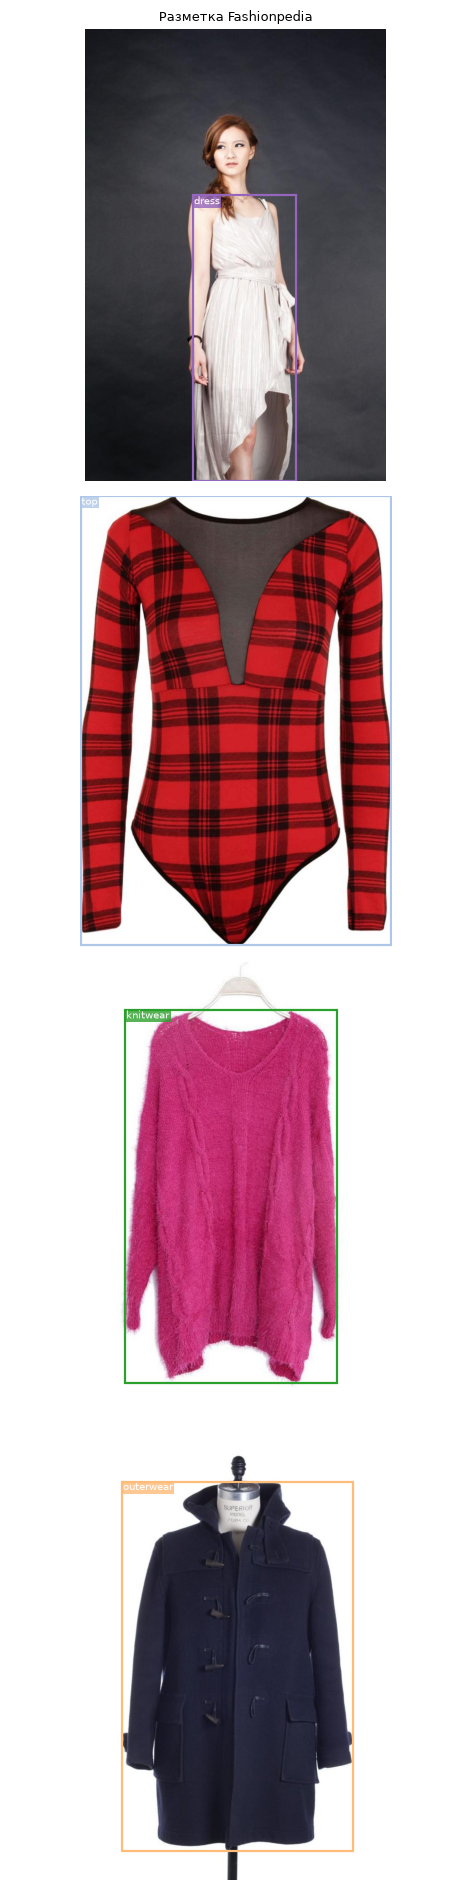

In [16]:
examples = SPLITS["train"][:4]
show_grid([[(imread_rgb(r["path"]), r["boxes"], r["labels"], CLASS_NAMES) for r in examples]],
          ["Разметка Fashionpedia"], RESULTS / "dataset_examples.png", width=5)

## 4. Предобученная модель до дообучения

Faster R-CNN из `torchvision` обучен на COCO: 80 классов, среди них `person`, `handbag`, `backpack`, `tie`, но ни одного предмета одежды. Поэтому на наших картинках модель «до» ожидаемо видит человека и иногда сумку.

Чтобы всё же измерить её число, считаем две величины:
- **mAP без учёта класса (class-agnostic):** все предсказания и все настоящие рамки считаются одним классом «объект». Показывает, насколько COCO-модель вообще обводит предметы одежды, а не только людей целиком.
- **AP для `bag`:** предсказания `handbag` и `backpack` переименовываются в `bag`, остальные отбрасываются. Это единственный класс, для которого у COCO-модели есть хоть какой-то аналог.

Эти же тестовые картинки в разделе 7 покажут предсказания до и после дообучения.

COCO-модель на тесте: 100%|██████████| 289/289 [06:54<00:00,  1.44s/it]


**COCO-модель без дообучения на тесте.** Без учёта класса: mAP@[.5:.95] = 0.011, mAP@.5 = 0.044. AP для `bag` через handbag/backpack: AP@[.5:.95] = 0.291, AP@.5 = 0.489.

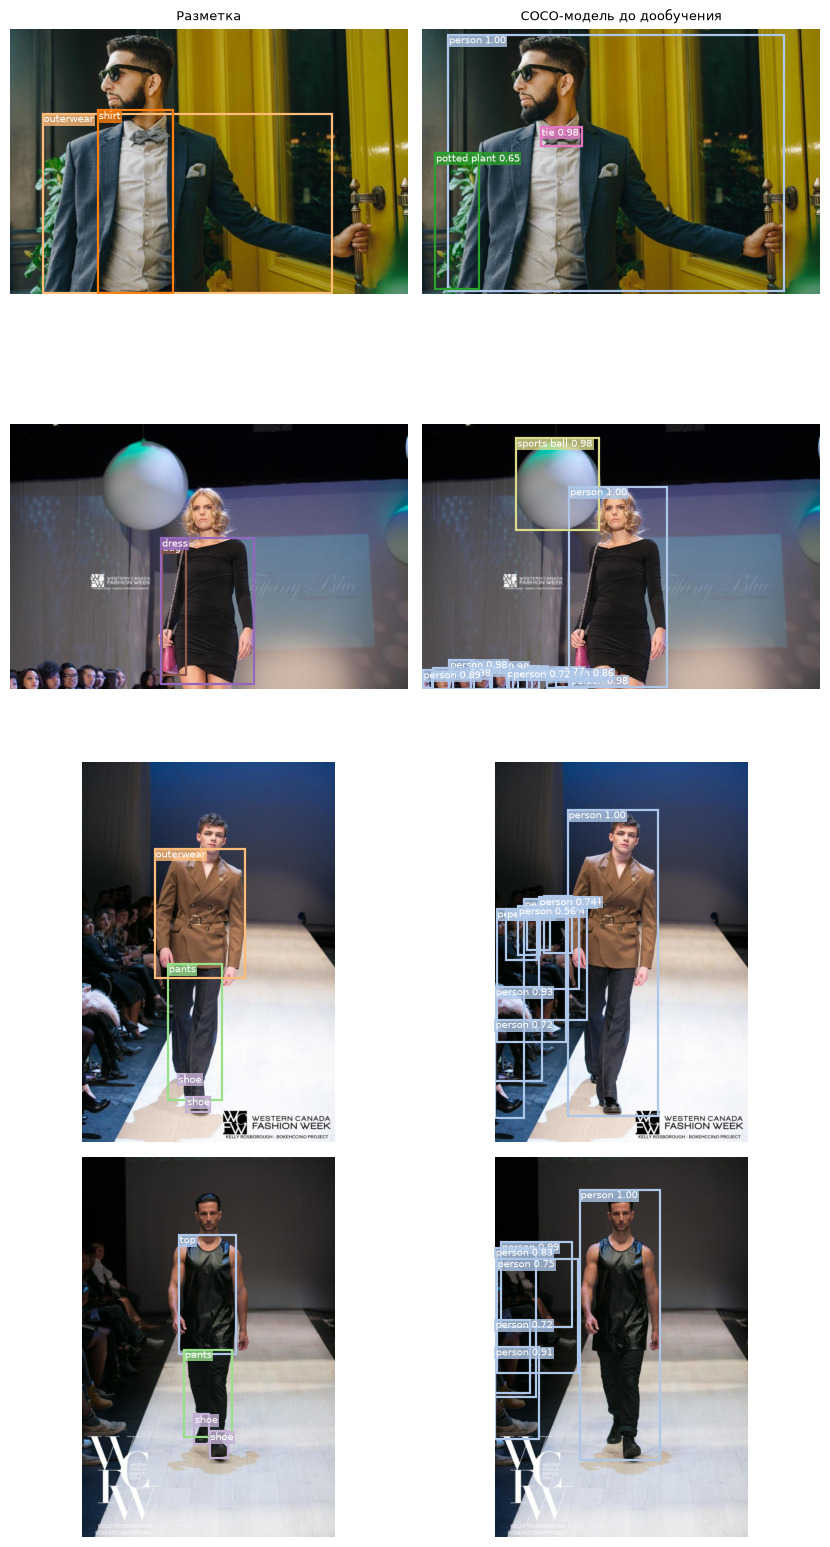

In [ ]:
COCO_WEIGHTS = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
COCO_NAMES = COCO_WEIGHTS.meta["categories"]


def build_model(num_classes=None):
    model = fasterrcnn_resnet50_fpn_v2(weights=COCO_WEIGHTS, min_size=TRAIN_CFG["min_size"], max_size=TRAIN_CFG["max_size"],
                                       trainable_backbone_layers=TRAIN_CFG["trainable_backbone_layers"])
    if num_classes:
        in_features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model.to(device)


@torch.no_grad()
def predict(model, records, batch_size=4, threads=4, desc="predict"):
    # список словарей {boxes, labels, scores} (numpy) в порядке records
    model.eval()
    model.roi_heads.score_thresh = 0.01    # низкий порог: для mAP нужны и неуверенные детекции
    model.roi_heads.detections_per_img = 100
    out = []
    with ThreadPoolExecutor(threads) as pool:
        for start in tqdm(range(0, len(records), batch_size), desc=desc):
            imgs = list(pool.map(lambda r: to_tensor(imread_rgb(r["path"])).to(device), records[start:start + batch_size]))
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
                preds = model(imgs)
            out += [{k: (v.cpu().numpy().astype(np.int64) if k == "labels" else v.float().cpu().numpy()) for k, v in p.items()} for p in preds]
    return out


def store_preds(path, records, preds):
    # Вместе с предсказаниями сохраняется список картинок: кэш от другой выборки не будет использован
    write_json(path, {"ids": [r["id"] for r in records], "preds": [{k: v.tolist() for k, v in p.items()} for p in preds]})


def cached_preds(path, records):
    if not Path(path).exists():
        return None
    obj = read_json(path)
    if not isinstance(obj, dict) or obj.get("ids") != [r["id"] for r in records]:
        return None
    return [{k: np.asarray(v, dtype=np.float32 if k != "labels" else np.int64) for k, v in p.items()} for p in obj["preds"]]


# ---------- mAP через pycocotools ----------
IOU_THRS = np.linspace(0.5, 0.95, 10)


def make_coco_gt(records, names):
    coco, anns = COCO(), []
    for r in records:
        for box, label in zip(r["boxes"], r["labels"]):
            x1, y1, x2, y2 = box
            anns.append({"id": len(anns) + 1, "image_id": r["id"], "category_id": int(label), "bbox": [x1, y1, x2 - x1, y2 - y1],
                         "area": (x2 - x1) * (y2 - y1), "iscrowd": 0})
    coco.dataset = {"images": [{"id": r["id"], "width": r["width"], "height": r["height"]} for r in records],
                    "categories": [{"id": i, "name": n} for i, n in enumerate(names) if i > 0], "annotations": anns}
    with redirect_stdout(io.StringIO()):
        coco.createIndex()
    return coco


def evaluate_map(records, preds, names):
    # Стандартная оценка COCO
    gt = make_coco_gt(records, names)
    dets = [{"image_id": r["id"], "category_id": int(l), "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
             "score": float(s)} for r, p in zip(records, preds) for b, l, s in zip(p["boxes"], p["labels"], p["scores"])]
    empty = {"mAP": 0.0, "AP50": 0.0, "AP75": 0.0, "APs": 0.0, "APm": 0.0, "APl": 0.0,
             "per_iou": {f"{t:.2f}": 0.0 for t in IOU_THRS}, "per_class": {n: {"AP": 0.0, "AP50": 0.0, "AP75": 0.0} for n in names[1:]}}
    if not dets:
        return empty
    with redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dets)
        ev = COCOeval(gt, dt, "bbox")
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    prec = ev.eval["precision"]   # [порог IoU, recall, класс, размер объекта, max dets]
    res = {"mAP": float(ev.stats[0]), "AP50": float(ev.stats[1]), "AP75": float(ev.stats[2]),
           "APs": float(ev.stats[3]), "APm": float(ev.stats[4]), "APl": float(ev.stats[5]), "per_iou": {}, "per_class": {}}
    for t, thr in enumerate(ev.params.iouThrs):
        p = prec[t, :, :, 0, -1]
        res["per_iou"][f"{thr:.2f}"] = float(p[p > -1].mean()) if (p > -1).any() else 0.0
    for k, cat_id in enumerate(ev.params.catIds):
        p_all, p50, p75 = prec[:, :, k, 0, -1], prec[0, :, k, 0, -1], prec[5, :, k, 0, -1]
        res["per_class"][names[cat_id]] = {"AP": float(p_all[p_all > -1].mean()) if (p_all > -1).any() else float("nan"),
                                           "AP50": float(p50[p50 > -1].mean()) if (p50 > -1).any() else float("nan"),
                                           "AP75": float(p75[p75 > -1].mean()) if (p75 > -1).any() else float("nan")}
    return res


def class_agnostic(records, preds):
    recs = [{**r, "labels": [1] * len(r["labels"])} for r in records]
    prs = [{**p, "labels": np.ones_like(p["labels"])} for p in preds]
    return recs, prs, ["__background__", "object"]


def remap_coco_to_bag(preds):
    bag_ids = {COCO_NAMES.index("handbag"), COCO_NAMES.index("backpack")}
    out = []
    for p in preds:
        keep = np.array([int(l) in bag_ids for l in p["labels"]], dtype=bool)
        out.append({"boxes": p["boxes"][keep], "scores": p["scores"][keep],
                    "labels": np.full(int(keep.sum()), CLASS_NAMES.index("bag"), dtype=np.int64)})
    return out


def evaluate_before(records):
    path = RESULTS / "before" / "test_predictions.json"
    preds = cached_preds(path, records)
    if preds is None:
        preds = predict(build_model(), records, desc="COCO-модель на тесте")
        store_preds(path, records, preds)
    res = {"class_agnostic": evaluate_map(*class_agnostic(records, preds)),
           "bag_from_handbag": evaluate_map(records, remap_coco_to_bag(preds), CLASS_NAMES)["per_class"]["bag"]}
    write_json(RESULTS / "before" / "metrics.json", res)
    return preds, res


before_preds, before = evaluate_before(SPLITS["test"])
ca = before["class_agnostic"]
display(Markdown(f"**COCO-модель без дообучения на тесте.** Без учёта класса: mAP@[.5:.95] = {ca['mAP']:.3f}, "
                 f"mAP@.5 = {ca['AP50']:.3f}. AP для `bag` через handbag/backpack: AP@[.5:.95] = {before['bag_from_handbag']['AP']:.3f}, "
                 f"AP@.5 = {before['bag_from_handbag']['AP50']:.3f}."))

# Предсказания COCO-модели на первых тестовых картинках (показываются детекции с уверенностью ≥ 0,5)
def confident(p, thr=0.5):
    keep = p["scores"] >= thr
    return p["boxes"][keep], p["labels"][keep], p["scores"][keep]

examples = SPLITS["test"][:4]
show_grid([[(imread_rgb(r["path"]), r["boxes"], r["labels"], CLASS_NAMES) for r in examples],
           [(imread_rgb(r["path"]), *confident(p)[:2], COCO_NAMES, confident(p)[2]) for r, p in zip(examples, before_preds)]],
          ["Разметка", "COCO-модель до дообучения"], RESULTS / "before" / "examples.png")

## 5. Дообучение

- **Что обучается.** Голова детекции создаётся заново (10 классов + фон), RPN и верхние три стадии ResNet-50 дообучаются, первые слои backbone заморожены: низкоуровневые признаки от COCO подходят любым фотографиям.
- **Оптимизатор.** SGD с momentum 0,9 и weight decay 10⁻⁴, как в статье и в референсе `torchvision`. Темп 0,005 для батча из 4 картинок, линейный разогрев 500 итераций, затем снижение в 10 раз после 7-й и 9-й эпох. Всего 10 эпох по 1500 итераций.
- **Аугментации.** Горизонтальное отражение и случайные яркость/контраст. Масштаб меняет сама модель: картинка приводится к 640 px по короткой стороне.
- **Точность.** bf16 autocast на GPU. Потери считаются во float32 внутри `torchvision`.
- **Данные.** Батчи собираются в пуле потоков, пока GPU считает предыдущий (процессы в Jupyter на Windows не работают).
- **Валидация.** После каждой эпохи считается mAP на валидации; лучшие веса по mAP@[.5:.95] сохраняются в `checkpoints/<имя>/best.pt`.
- **Логи.** `results/<имя>/train_log.csv` (потери по компонентам: классификация, регрессия рамок, objectness RPN, регрессия RPN), `val_log.csv`, `curves.png`.
- **Прерывание.** *Interrupt* сохраняет чекпоинт последней завершённой эпохи; повторный запуск ячейки продолжает. Начать заново: `restart=True`.

In [ ]:
class DetDataset:
    def __init__(self, records, train):
        self.records, self.train = records, train

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        img = imread_rgb(r["path"])
        boxes = np.array(r["boxes"], dtype=np.float32).reshape(-1, 4)
        if self.train:
            if random.random() < 0.5:   # горизонтальное отражение: x1' = w − x2, x2' = w − x1
                img = img[:, ::-1]
                boxes[:, [0, 2]] = r["width"] - boxes[:, [2, 0]]
            if random.random() < 0.8:   # яркость/контраст
                img = cv2.convertScaleAbs(img, alpha=random.uniform(0.75, 1.25), beta=random.uniform(-20, 20))
        target = {"boxes": torch.from_numpy(boxes), "labels": torch.tensor(r["labels"], dtype=torch.int64)}
        return to_tensor(img), target


def batch_iter(ds, indices, batch_size, threads, prefetch=4):
    # Следующие батчи готовятся в потоках заранее
    chunks = [indices[i:i + batch_size] for i in range(0, len(indices), batch_size)]
    pool = ThreadPoolExecutor(threads)
    load = lambda chunk: [ds[j] for j in chunk]
    queue = deque(pool.submit(load, c) for c in chunks[:prefetch])
    try:
        for c in chunks[prefetch:]:
            queue.append(pool.submit(load, c))
            yield queue.popleft().result()
        while queue:
            yield queue.popleft().result()
    finally:
        pool.shutdown(wait=False, cancel_futures=True)


class CsvLog:
    def __init__(self, path, fields, keep_upto, key):
        self.path, self.fields = path, fields
        rows = []
        if keep_upto > 0 and path.exists():
            with open(path, newline="", encoding="utf-8") as f:
                rows = [r for r in csv.DictReader(f) if float(r[key]) <= keep_upto]
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fields, extrasaction="ignore")
            w.writeheader()
            w.writerows(rows)

    def write(self, row):
        with open(self.path, "a", newline="", encoding="utf-8") as f:
            csv.DictWriter(f, self.fields, extrasaction="ignore").writerow(
                {k: f"{v:.6g}" if isinstance(v, float) else v for k, v in row.items()})


def read_csv(path):
    if not Path(path).exists():
        return []
    with open(path, newline="", encoding="utf-8") as f:
        return [{k: float(v) for k, v in r.items() if v} for r in csv.DictReader(f)]


def fmt_duration(seconds):
    m = int(seconds // 60)
    return f"{m // 60} ч {m % 60:02d} мин" if m >= 60 else f"{m} мин"


def lr_at(it, epoch, cfg, iters_per_epoch):
    # Линейный разогрев, затем ступенчатое снижение в 10 раз после заданных эпох
    warm = min(1.0, (it + 1) / max(1, cfg["warmup_iters"]))
    drops = sum(epoch > e for e in cfg["lr_drop_epochs"])
    return cfg["lr"] * warm * 0.1 ** drops


def train_model(cfg, restart=False):
    name, run_dir, ckpt_dir = cfg["name"], RESULTS / cfg["name"], CKPT / cfg["name"]
    ckpt_path = ckpt_dir / "latest.pt"
    restart = restart or SMOKE
    seed_everything(SEED)
    write_json(run_dir / "env.json", env_info())
    write_json(run_dir / "config.json", {**cfg, "data": DATA_CFG, "classes": CLASS_NAMES})

    model = build_model(NUM_CLASSES)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = SGD(params, lr=cfg["lr"], momentum=cfg["momentum"], weight_decay=cfg["weight_decay"])
    start_epoch, best, elapsed_before = 0, None, 0.0
    if ckpt_path.exists() and not restart:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        start_epoch, best, elapsed_before = ck["epoch"], ck["best"], ck["elapsed"]
        print(f"Продолжаю с эпохи {start_epoch + 1}")
    if start_epoch >= cfg["epochs"]:
        print("Модель уже обучена. Для переобучения: restart=True")
        return read_json(run_dir / "summary.json")

    train_ds = DetDataset(SPLITS["train"], train=True)
    iters_per_epoch = (len(train_ds) + cfg["batch_size"] - 1) // cfg["batch_size"]
    if cfg["max_iters_per_epoch"]:
        iters_per_epoch = min(iters_per_epoch, cfg["max_iters_per_epoch"])
    loss_keys = ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]
    train_log = CsvLog(run_dir / "train_log.csv", ["iter", "epoch", "lr", "loss", *loss_keys, "it_per_s", "mem_gb"],
                       start_epoch * iters_per_epoch, "iter")
    val_log = CsvLog(run_dir / "val_log.csv", ["epoch", "mAP", "AP50", "AP75", "elapsed_min"], start_epoch, "epoch")
    print(f"Обучение: {len(train_ds)} картинок, {iters_per_epoch} итераций в эпохе, {cfg['epochs']} эпох; val: {len(SPLITS['val'])}")

    def checkpoint(epoch):
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        state = {"epoch": epoch, "best": best, "elapsed": elapsed_before + time.time() - t_start,
                 "model": model.state_dict(), "opt": opt.state_dict()}
        torch.save(state, ckpt_path.with_suffix(".tmp"))
        ckpt_path.with_suffix(".tmp").replace(ckpt_path)   # атомарно: прерывание не портит прошлый чекпоинт

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_start = time.time()
    it = start_epoch * iters_per_epoch
    try:
        for epoch in range(start_epoch + 1, cfg["epochs"] + 1):
            model.train()
            indices = list(range(len(train_ds)))
            random.shuffle(indices)
            indices = indices[: iters_per_epoch * cfg["batch_size"]]
            acc, n_acc, t_window = defaultdict(float), 0, time.time()
            pbar = tqdm(batch_iter(train_ds, indices, cfg["batch_size"], cfg["loader_threads"]),
                        total=iters_per_epoch, desc=f"эпоха {epoch}/{cfg['epochs']}")
            for batch in pbar:
                lr = lr_at(it, epoch, cfg, iters_per_epoch)
                for g in opt.param_groups:
                    g["lr"] = lr
                images = [img.to(device, non_blocking=True) for img, _ in batch]
                targets = [{k: v.to(device) for k, v in t.items()} for _, t in batch]
                with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
                    loss_dict = model(images, targets)
                loss = sum(loss_dict.values())
                opt.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params, 10.0)
                opt.step()
                it, n_acc = it + 1, n_acc + 1
                acc["loss"] += loss.detach()
                for k in loss_keys:
                    acc[k] += loss_dict[k].detach()
                if it % cfg["log_every"] == 0:
                    mem = torch.cuda.max_memory_allocated() / 2 ** 30 if device.type == "cuda" else 0.0
                    means = {k: float(v) / n_acc for k, v in acc.items()}
                    train_log.write({"iter": it, "epoch": epoch, "lr": lr, "it_per_s": n_acc / (time.time() - t_window),
                                     "mem_gb": mem, **means})
                    pbar.set_postfix(loss=f"{means['loss']:.3f}", cls=f"{means['loss_classifier']:.3f}",
                                     box=f"{means['loss_box_reg']:.3f}", VRAM=f"{mem:.1f}G")
                    acc, n_acc, t_window = defaultdict(float), 0, time.time()
            pbar.close()

            res = evaluate_map(SPLITS["val"], predict(model, SPLITS["val"], desc="val"), CLASS_NAMES)
            val_log.write({"epoch": epoch, "mAP": res["mAP"], "AP50": res["AP50"], "AP75": res["AP75"],
                           "elapsed_min": (elapsed_before + time.time() - t_start) / 60})
            mark = ""
            if best is None or res["mAP"] > best:
                best = res["mAP"]
                ckpt_dir.mkdir(parents=True, exist_ok=True)
                torch.save(model.state_dict(), ckpt_dir / "best.pt")
                mark = "  ← лучшая"
            print(f"[эпоха {epoch}] val: mAP@[.5:.95] {res['mAP']:.3f}, mAP@.5 {res['AP50']:.3f}, mAP@.75 {res['AP75']:.3f}{mark}")
            checkpoint(epoch)
    except KeyboardInterrupt:
        print("Остановлено. Чекпоинт последней завершённой эпохи сохранён - повторный запуск ячейки продолжит обучение.")
        return None

    total = elapsed_before + time.time() - t_start
    summary = {"name": name, "epochs": cfg["epochs"], "iterations": it, "total_time": fmt_duration(total), "best_val_mAP": best}
    if device.type == "cuda":
        summary["max_vram_gb"] = round(torch.cuda.max_memory_allocated() / 2 ** 30, 2)
    write_json(run_dir / "summary.json", summary)
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary


def plot_curves(name):
    run = RESULTS / name
    train, val = read_csv(run / "train_log.csv"), read_csv(run / "val_log.csv")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for k in ["loss", "loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
        axes[0].plot([r["iter"] for r in train], [r[k] for r in train], label=k, linewidth=1)
    axes[0].set_yscale("log")
    axes[0].set_title("Потери на обучении")
    axes[0].set_xlabel("итерация")
    axes[1].plot([r["iter"] for r in train], [r["lr"] for r in train])
    axes[1].set_title("Темп обучения")
    axes[1].set_xlabel("итерация")
    for k in ["mAP", "AP50", "AP75"]:
        axes[2].plot([r["epoch"] for r in val], [r[k] for r in val], marker=".", label=k)
    axes[2].set_title("Валидация")
    axes[2].set_xlabel("эпоха")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    axes[2].legend()
    fig.tight_layout()
    fig.savefig(run / "curves.png", dpi=110)
    plt.show()

Обучение: 6000 картинок, 1500 итераций в эпохе, 10 эпох; val: 600
val: 100%|██████████| 150/150 [00:37<00:00,  3.95it/s]
[эпоха 1] val: mAP@[.5:.95] 0.425, mAP@.5 0.597, mAP@.75 0.484  ← лучшая
val: 100%|██████████| 150/150 [00:24<00:00,  6.14it/s]
[эпоха 2] val: mAP@[.5:.95] 0.482, mAP@.5 0.653, mAP@.75 0.542  ← лучшая
val: 100%|██████████| 150/150 [00:24<00:00,  6.21it/s]
[эпоха 3] val: mAP@[.5:.95] 0.476, mAP@.5 0.650, mAP@.75 0.543
val: 100%|██████████| 150/150 [02:56<00:00,  1.18s/it]
[эпоха 4] val: mAP@[.5:.95] 0.517, mAP@.5 0.687, mAP@.75 0.588  ← лучшая
val: 100%|██████████| 150/150 [00:27<00:00,  5.42it/s]
[эпоха 5] val: mAP@[.5:.95] 0.520, mAP@.5 0.691, mAP@.75 0.576  ← лучшая
val: 100%|██████████| 150/150 [00:24<00:00,  6.17it/s]
[эпоха 6] val: mAP@[.5:.95] 0.513, mAP@.5 0.683, mAP@.75 0.585
val: 100%|██████████| 150/150 [00:24<00:00,  6.22it/s]
[эпоха 7] val: mAP@[.5:.95] 0.505, mAP@.5 0.676, mAP@.75 0.572
val: 100%|██████████| 150/150 [00:24<00:00,  6.23it/s]
[эпоха 8] val

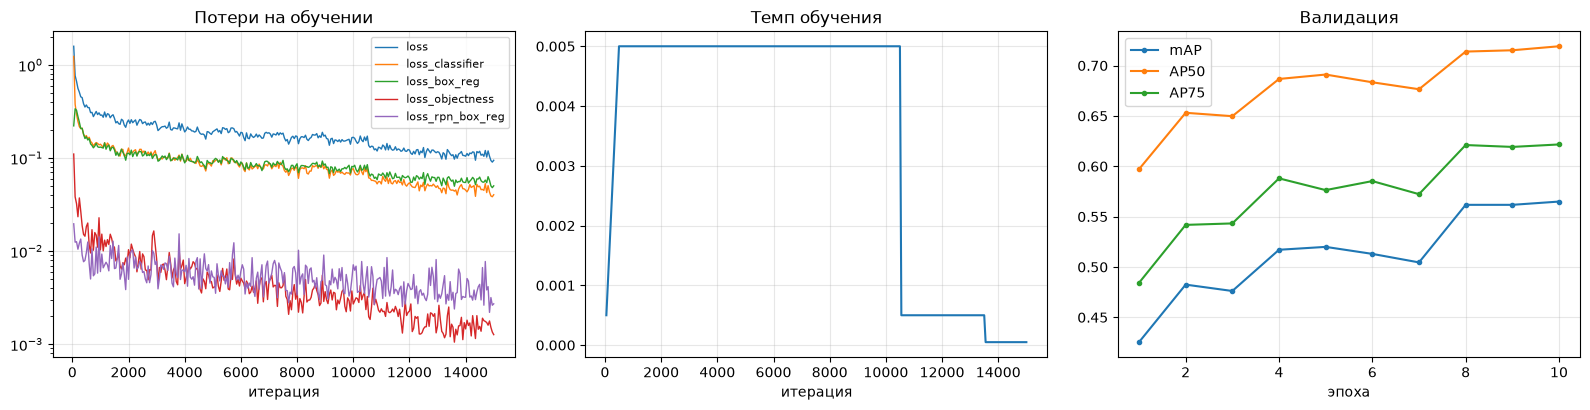

In [19]:
print(train_model(TRAIN_CFG))
plot_curves(TRAIN_CFG["name"])

## 6. Оценка на тесте: mAP при разных порогах IoU

Лучшие по валидации веса прогоняются по тестовой выборке (официальный val Fashionpedia, 1158 картинок, модель их не видела). Считаются:
- стандартные числа COCO: mAP@[.5:.95], mAP@.5, mAP@.75 и mAP по размерам объектов (small < 32², medium, large > 96² пикселей);
- mAP при каждом из 10 порогов IoU от 0,50 до 0,95: кривая показывает, насколько точно модель ставит рамки, а не только находит объекты;
- AP по каждому классу.

Для сравнения в таблицу добавлены числа COCO-модели до дообучения из раздела 4.

тест: 100%|██████████| 289/289 [00:47<00:00,  6.03it/s]


| Модель | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP small | AP medium | AP large |
|---|---|---|---|---|---|---|
| COCO-модель, без учёта класса | 0.011 | 0.044 | 0.003 | 0.000 | 0.001 | 0.019 |
| Дообученная, без учёта класса | 0.643 | 0.887 | 0.732 | 0.156 | 0.635 | 0.684 |
| **Дообученная, 10 классов** | **0.529** | **0.695** | **0.583** | 0.285 | 0.336 | 0.551 |

| Порог IoU | 0.50 | 0.55 | 0.60 | 0.65 | 0.70 | 0.75 | 0.80 | 0.85 | 0.90 | 0.95 |
|---|---|---|---|---|---|---|---|---|---|---|
| mAP | 0.695 | 0.682 | 0.666 | 0.648 | 0.620 | 0.583 | 0.542 | 0.461 | 0.323 | 0.076 |


| Класс | AP@[.5:.95] | AP@.5 | AP@.75 | рамок в тесте |
|---|---|---|---|---|
| top | 0.524 | 0.730 | 0.566 | 477 |
| shirt | 0.297 | 0.424 | 0.303 | 102 |
| outerwear | 0.625 | 0.787 | 0.698 | 287 |
| knitwear | 0.187 | 0.235 | 0.197 | 33 |
| pants | 0.716 | 0.889 | 0.778 | 314 |
| shorts | 0.596 | 0.759 | 0.667 | 106 |
| skirt | 0.534 | 0.631 | 0.608 | 162 |
| dress | 0.750 | 0.919 | 0.818 | 508 |
| shoe | 0.637 | 0.911 | 0.744 | 1566 |
| bag | 0.429 | 0.668 | 0.448 | 214 |
| bag у COCO-модели (handbag/backpack) | 0.291 | 0.489 | 0.299 | |


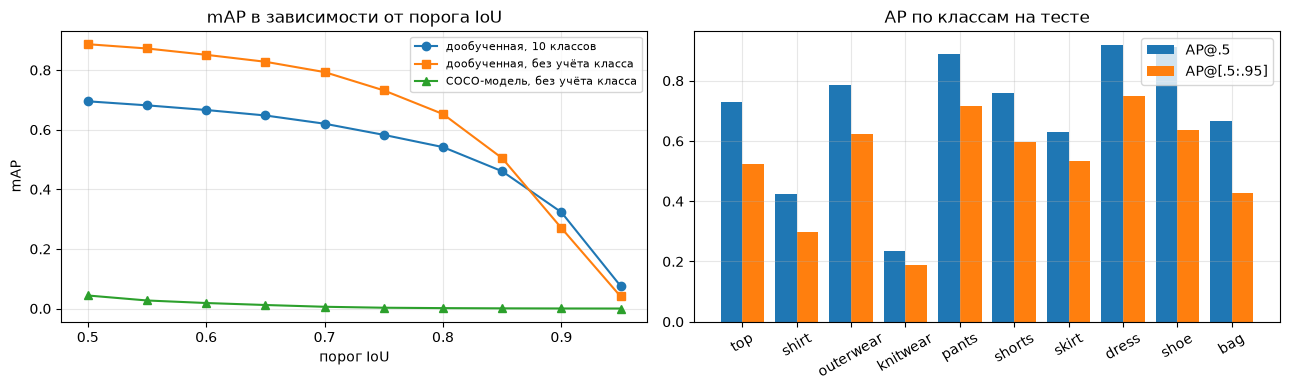

In [20]:
def load_best(cfg):
    model = build_model(NUM_CLASSES)
    model.load_state_dict(torch.load(CKPT / cfg["name"] / "best.pt", map_location=device, weights_only=True))
    return model


def evaluate_test(cfg):
    out = RESULTS / "eval"
    pred_path = out / "test_predictions.json"
    preds = cached_preds(pred_path, SPLITS["test"])
    if preds is None:
        preds = predict(load_best(cfg), SPLITS["test"], desc="тест")
        store_preds(pred_path, SPLITS["test"], preds)
    res = evaluate_map(SPLITS["test"], preds, CLASS_NAMES)
    res["class_agnostic"] = evaluate_map(*class_agnostic(SPLITS["test"], preds))
    write_json(out / "metrics.json", res)
    return preds, res


after_preds, after = evaluate_test(TRAIN_CFG)
ca_before, ca_after = before["class_agnostic"], after["class_agnostic"]

def metrics_row(title, m, bold=False):
    cells = [f"{m[k]:.3f}" for k in ("mAP", "AP50", "AP75", "APs", "APm", "APl")]
    if bold:
        title, cells = f"**{title}**", [f"**{c}**" for c in cells[:3]] + cells[3:]
    return f"| {title} | " + " | ".join(cells) + " |"


display(Markdown("\n".join([
    "| Модель | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP small | AP medium | AP large |",
    "|---|---|---|---|---|---|---|",
    metrics_row("COCO-модель, без учёта класса", ca_before),
    metrics_row("Дообученная, без учёта класса", ca_after),
    metrics_row("Дообученная, 10 классов", after, bold=True),
])))

iou_table = "| Порог IoU | " + " | ".join(after["per_iou"]) + " |\n|---|" + "---|" * len(after["per_iou"]) + "\n"
iou_table += "| mAP | " + " | ".join(f"{v:.3f}" for v in after["per_iou"].values()) + " |\n"
display(Markdown(iou_table))

cls_table = "| Класс | AP@[.5:.95] | AP@.5 | AP@.75 | рамок в тесте |\n|---|---|---|---|---|\n"
test_counts = Counter(CLASS_NAMES[l] for r in SPLITS["test"] for l in r["labels"])
for n, v in after["per_class"].items():
    cls_table += f"| {n} | {v['AP']:.3f} | {v['AP50']:.3f} | {v['AP75']:.3f} | {test_counts[n]} |\n"
cls_table += f"| bag у COCO-модели (handbag/backpack) | {before['bag_from_handbag']['AP']:.3f} | {before['bag_from_handbag']['AP50']:.3f} | {before['bag_from_handbag']['AP75']:.3f} | |\n"
display(Markdown(cls_table))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
thrs = [float(t) for t in after["per_iou"]]
axes[0].plot(thrs, list(after["per_iou"].values()), marker="o", label="дообученная, 10 классов")
axes[0].plot(thrs, list(ca_after["per_iou"].values()), marker="s", label="дообученная, без учёта класса")
axes[0].plot(thrs, list(ca_before["per_iou"].values()), marker="^", label="COCO-модель, без учёта класса")
axes[0].set_xlabel("порог IoU")
axes[0].set_ylabel("mAP")
axes[0].set_title("mAP в зависимости от порога IoU")
axes[0].legend(fontsize=8)
names = list(after["per_class"])
x = np.arange(len(names))
axes[1].bar(x - 0.2, [after["per_class"][n]["AP50"] for n in names], width=0.4, label="AP@.5")
axes[1].bar(x + 0.2, [after["per_class"][n]["AP"] for n in names], width=0.4, label="AP@[.5:.95]")
axes[1].set_xticks(x, names, rotation=30)
axes[1].set_title("AP по классам на тесте")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS / "eval" / "map_vs_iou.png", dpi=110)
plt.show()

## 7. Предсказания до и после дообучения

Одни и те же тестовые картинки: разметка, COCO-модель до дообучения и дообученная модель. Показаны детекции с уверенностью не ниже 0,5.

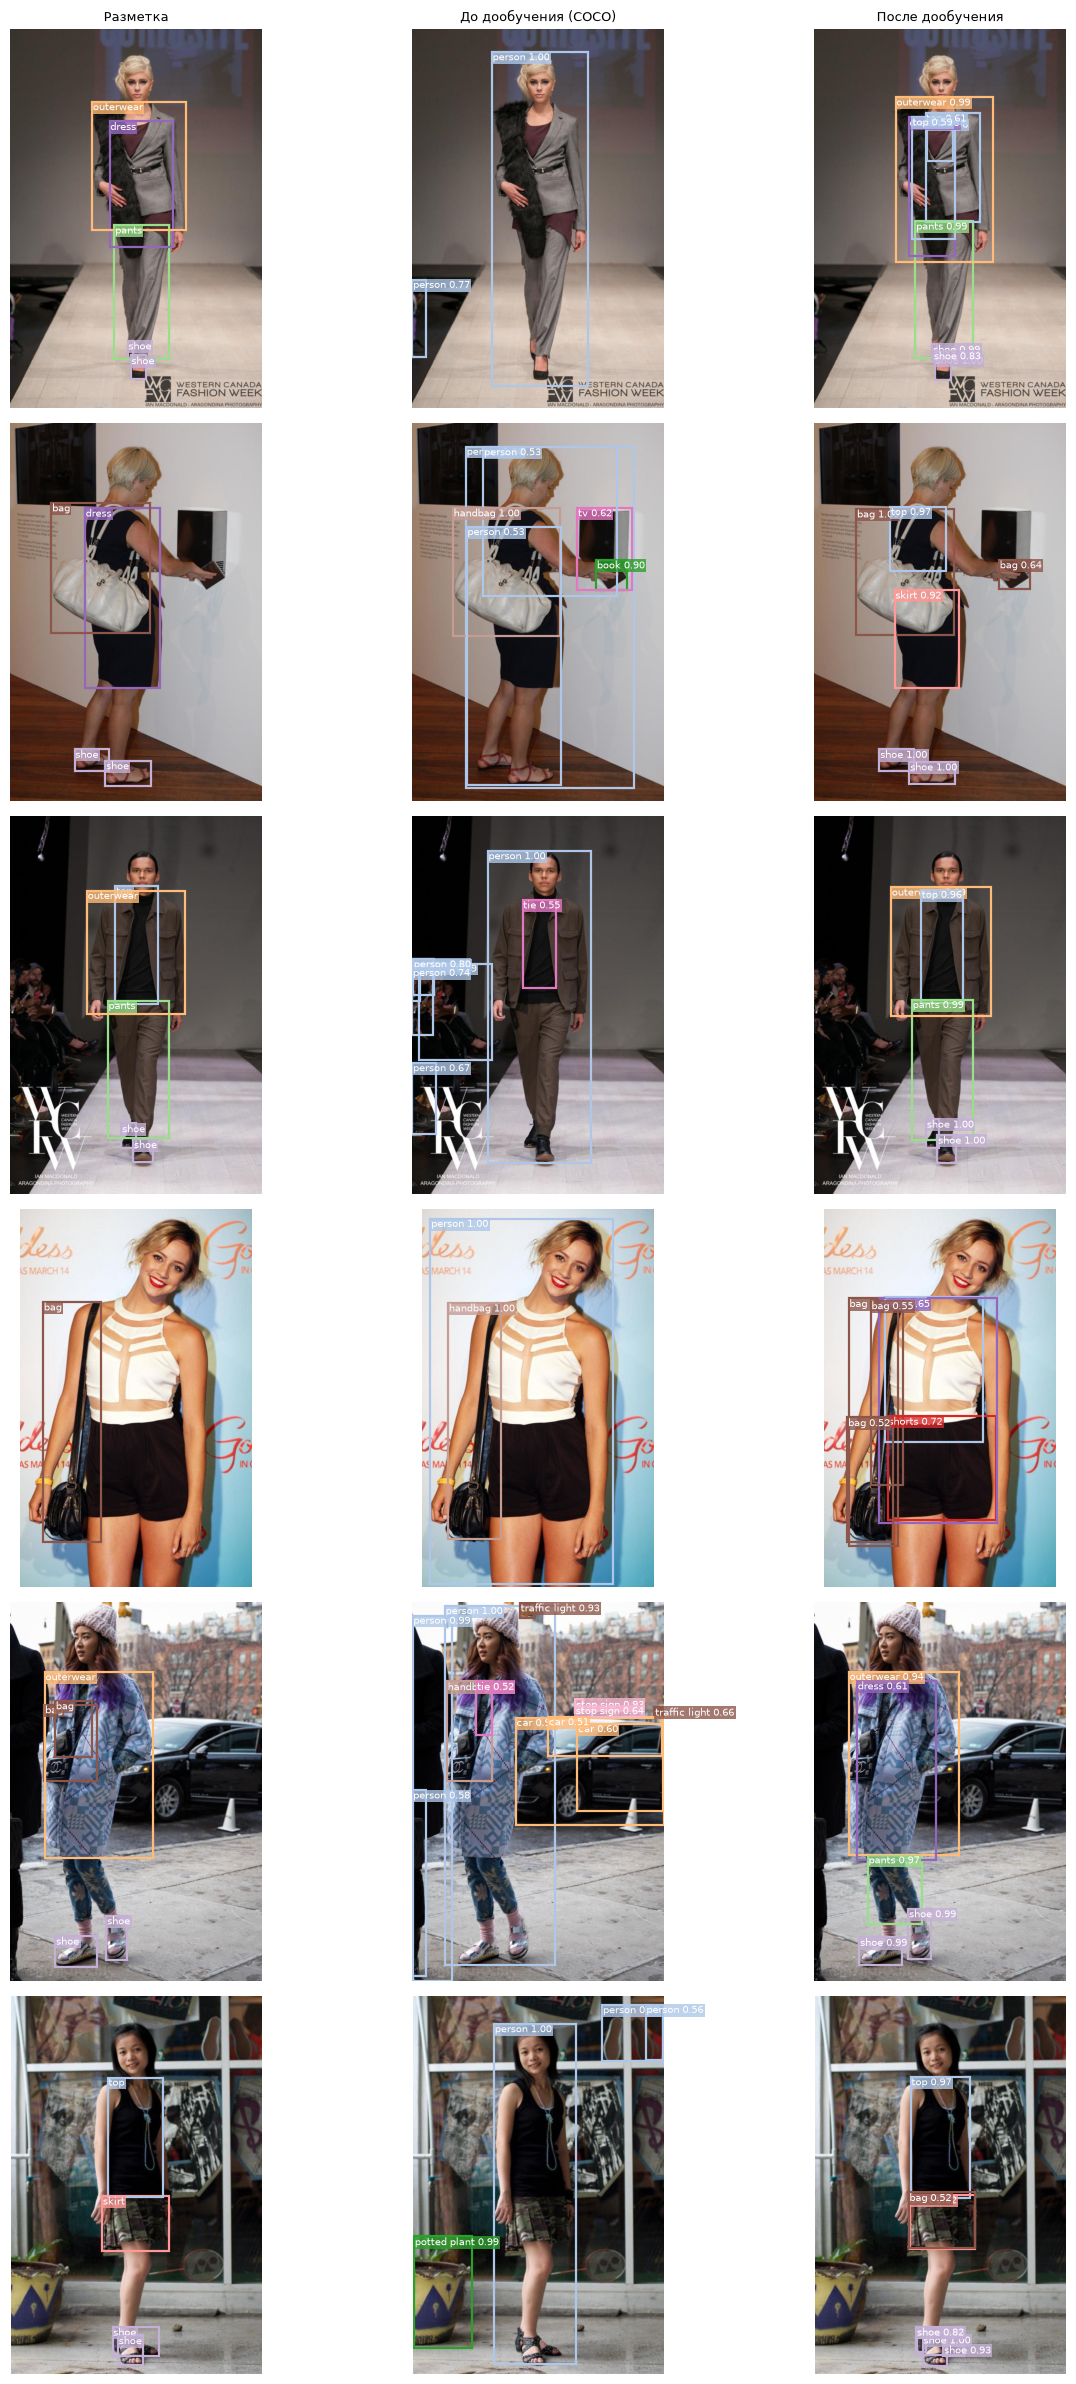

In [21]:
def show_before_after(indices, path, thr=0.5):
    recs = [SPLITS["test"][i] for i in indices]
    imgs = [imread_rgb(r["path"]) for r in recs]
    show_grid([[(img, r["boxes"], r["labels"], CLASS_NAMES) for img, r in zip(imgs, recs)],
               [(img, *confident(before_preds[i], thr)[:2], COCO_NAMES, confident(before_preds[i], thr)[2]) for img, i in zip(imgs, indices)],
               [(img, *confident(after_preds[i], thr)[:2], CLASS_NAMES, confident(after_preds[i], thr)[2]) for img, i in zip(imgs, indices)]],
              ["Разметка", "До дообучения (COCO)", "После дообучения"], path)


rng = random.Random(SEED)
chosen = sorted(rng.sample(range(len(SPLITS["test"])), min(6, len(SPLITS["test"]))))
show_before_after(chosen, RESULTS / "eval" / "examples_before_after.png")

## 8. Разбор ошибок и контрольные вопросы

**Матрица ошибок.** Каждая уверенная детекция (score ≥ 0,5) сопоставляется с настоящей рамкой по IoU ≥ 0,5. По диагонали верные детекции, вне диагонали путаница классов, столбец «фон» - пропущенные объекты, строка «фон» - ложные срабатывания на пустом месте. Для слоистой одежды ожидаемы ошибки `shirt ↔ top`, `outerwear ↔ knitwear`: рамки одинаковы, различие только в фактуре.

### Чем one-stage детекторы отличаются от two-stage?

| | Two-stage (Faster R-CNN) | One-stage (YOLO, SSD, RetinaNet) |
|---|---|---|
| Схема | Сначала RPN выделяет кандидатов без класса, затем голова классифицирует каждого и уточняет рамку | Класс и рамка предсказываются сразу для каждой ячейки сетки / якоря за один проход |
| Точность | Обычно выше, особенно для мелких объектов и точной локализации: второй этап работает с вырезанными признаками кандидата | Ниже на той же архитектуре; разрыв закрывают focal loss (RetinaNet), anchor-free головы и многолетняя эволюция YOLO |
| Скорость | Медленнее: RoIAlign и голова для ~1000 кандидатов | Быстрее, подходят для реального времени |
| Дисбаланс фон/объект | RPN отсеивает фон, голова видит сбалансированную выборку | Все якоря классифицируются сразу, фона в тысячи раз больше, нужны focal loss или hard negative mining |
| Дообучение | Достаточно заменить голову детекции | Заменяется выходной слой; обычно нужны свои якоря под размеры объектов |

### Какие ошибки чаще всего допускает модель при детекции?

1. **Путаница близких классов** при верной рамке: `shirt` и `top`, `outerwear` и `knitwear`. Это главная ошибка на одежде, видна в матрице ниже.
2. **Неточная локализация:** объект найден, но IoU ниже порога. Проявляется как падение mAP между порогами 0,5 и 0,75 (раздел 6). Для одежды границы размыты по определению: где кончается блузка под пиджаком.
3. **Пропуски мелких и перекрытых объектов:** обувь, сумка за спиной, вторые слои одежды. AP small в разделе 6 заметно ниже AP large.
4. **Дубликаты:** две рамки разного класса на одном предмете (`shirt` и `top` с уверенностью 0,6 и 0,5). NMS убирает дубликаты только внутри класса.
5. **Ложные срабатывания на фоне:** одежда на манекене, в витрине, на второстепенных людях, не размеченных в датасете.

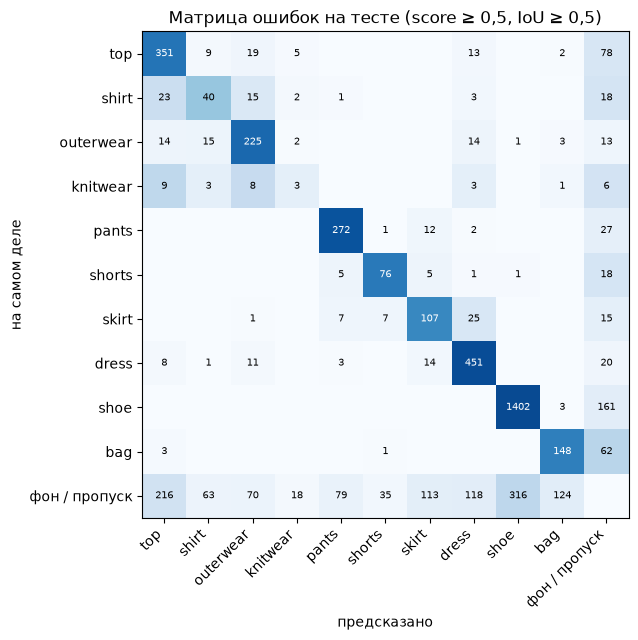

Настоящих рамок: 3769; найдено с верным классом: 3075 (81.6%); найдено, но класс перепутан: 276; пропущено: 418; ложных срабатываний на фоне: 1152
Самые частые путаницы (на самом деле → предсказано): skirt → dress: 25, shirt → top: 23, top → outerwear: 19, shirt → outerwear: 15, outerwear → shirt: 15


In [22]:
def box_iou_matrix(a, b):
    a, b = np.asarray(a, dtype=np.float32).reshape(-1, 4), np.asarray(b, dtype=np.float32).reshape(-1, 4)
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(axis=2)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def confusion_matrix(records, preds, thr=0.5, iou_thr=0.5):
    # строки — настоящий класс (последняя: фон/ложное срабатывание), столбцы — предсказанный (последний: пропуск)
    K = NUM_CLASSES - 1
    cm = np.zeros((K + 1, K + 1), dtype=int)
    for r, p in zip(records, preds):
        boxes, labels, scores = confident(p, thr)
        order = np.argsort(-scores)
        gt_boxes, gt_labels = np.array(r["boxes"]).reshape(-1, 4), np.array(r["labels"])
        matched_gt = np.zeros(len(gt_boxes), dtype=bool)
        ious = box_iou_matrix(boxes, gt_boxes) if len(boxes) and len(gt_boxes) else np.zeros((len(boxes), len(gt_boxes)))
        for i in order:
            cand = np.where((ious[i] >= iou_thr) & ~matched_gt)[0]
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]
                matched_gt[j] = True
                cm[gt_labels[j] - 1, labels[i] - 1] += 1
            else:
                cm[K, labels[i] - 1] += 1
        for j in np.where(~matched_gt)[0]:
            cm[gt_labels[j] - 1, K] += 1
    return cm


cm = confusion_matrix(SPLITS["test"], after_preds)
names = CLASS_NAMES[1:] + ["фон / пропуск"]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(names)):
    for j in range(len(names)):
        if cm[i, j]:
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7, color="white" if norm[i, j] > 0.5 else "black")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("предсказано")
ax.set_ylabel("на самом деле")
ax.set_title("Матрица ошибок на тесте (score ≥ 0,5, IoU ≥ 0,5)")
fig.tight_layout()
fig.savefig(RESULTS / "eval" / "confusion.png", dpi=110)
plt.show()

K = NUM_CLASSES - 1
total_gt = cm[:K].sum()
print(f"Настоящих рамок: {total_gt}; найдено с верным классом: {np.trace(cm[:K, :K])} ({np.trace(cm[:K, :K]) / max(total_gt, 1):.1%}); "
      f"найдено, но класс перепутан: {cm[:K, :K].sum() - np.trace(cm[:K, :K])}; пропущено: {cm[:K, K].sum()}; "
      f"ложных срабатываний на фоне: {cm[K, :K].sum()}")
pairs = sorted(((cm[i, j], names[i], names[j]) for i in range(K) for j in range(K) if i != j and cm[i, j]), reverse=True)[:5]
print("Самые частые путаницы (на самом деле → предсказано):", ", ".join(f"{a} → {b}: {n}" for n, a, b in pairs) or "нет")

## 9. Выводы

**Итог на тестовой выборке** (1155 картинок официального val Fashionpedia, 3769 размеченных предметов):

| Модель | mAP@[.5:.95] | mAP@.5 | mAP@.75 |
|---|---|---|---|
| COCO-модель до дообучения, без учёта класса | 0,011 | 0,044 | 0,003 |
| COCO-модель до дообучения, `bag` через handbag/backpack | 0,291 | 0,489 | 0,299 |
| Дообученная, без учёта класса | 0,643 | 0,887 | 0,732 |
| **Дообученная, 10 классов** | **0,529** | **0,695** | **0,583** |

1. **Дообучение сделало то, чего COCO-модель не умела вовсе.** До дообучения модель видела на фотографиях людей, сумки и случайные предметы (`tie`, `tv`, `potted plant`), а предметы одежды не обводила: mAP@.5 без учёта класса 0,044. После 10 эпох (15 000 итераций, 2 ч 07 мин на RTX 5060, 6,4 ГБ видеопамяти) она находит 82 % размеченных предметов с верным классом, mAP@.5 по 10 классам 0,695. Даже для `bag`, единственного класса с аналогом в COCO, AP вырос с 0,291 до 0,429.

2. **Рамки точные, слабое место — классификация.** Без учёта класса дообученная модель даёт mAP@.5 = 0,887, с классами 0,695: почти вся разница в 0,19 приходится на путаницу похожих предметов. Кривая mAP по порогу IoU снижается плавно: 0,695 при 0,5, 0,583 при 0,75, 0,542 при 0,8, и лишь выше 0,85 обваливается (0,323 при 0,9, 0,076 при 0,95). Значит, рамки обычно отклоняются от разметки не более чем на 10–15 % размера, а дальше начинает сказываться принципиальная размытость границ одежды: где кончается блузка под пиджаком, решает разметчик.

3. **Какие классы хуже и почему.** AP@[.5:.95] по классам: dress 0,750, pants 0,716, shoe 0,637, outerwear 0,625, shorts 0,596, skirt 0,534, top 0,524, bag 0,429, shirt 0,297, knitwear 0,187. Отстают два типа классов:
   - *редкие*: у knitwear 333 обучающих рамки против 6106 у shoe и всего 33 в тесте, у shirt 839;
   - *похожие на соседей*: самые частые путаницы в матрице ошибок — skirt → dress (25), shirt → top (23), top → outerwear (19), shirt ↔ outerwear (по 15). Это верхняя одежда с одинаковой рамкой и разной только фактурой, и юбка, которая вместе с топом выглядит как платье.
   Мелкие объекты тоже даются хуже: AP small 0,285 против AP large 0,551; это обувь и сумки на дальних планах.

4. **Структура ошибок** (score ≥ 0,5, IoU ≥ 0,5): из 3769 предметов 3075 найдены верно, 276 найдены с чужим классом, 418 пропущены (больше всего обуви: 161). Ложных срабатываний 1152, и большая их часть - не выдумка модели, а слоистость одежды и фон: вторая рамка другого класса на том же предмете (NMS подавляет дубликаты только внутри класса) и одежда зрителей на втором плане, которую Fashionpedia не размечает. На примерах из раздела 7 это видно: на модели с подиума рамки стоят верно, а вокруг появляются `bag 0,52` и `top 0,55` на неразмеченных людях.

5. **Ход обучения.** Валидационный mAP рос с 0,425 после первой эпохи до 0,565 после десятой. Самый большой скачок, с 0,505 до 0,562, дало снижение темпа обучения в 10 раз после 7-й эпохи: при lr 0,005 модель колебалась, при 0,0005 закрепилась. Потери на обучении продолжали снижаться, а валидация не падала, переобучения нет.

6. **Что можно улучшить.** Ещё 3–5 эпох на малом темпе (кривая валидации ещё не вышла на плато), многомасштабное обучение и большее разрешение для обуви и сумок, взвешивание или дополнительная выборка редких классов (knitwear, shirt), NMS между классами против двойных рамок на одном предмете, а для путаницы shirt/top/outerwear — признать, что по рамке они неразличимы, и либо объединить их, либо добавить атрибуты Fashionpedia (длина рукава, застёжка) как вторую задачу.

### Ответы на контрольные вопросы

Подробные ответы даны в разделе 8. Коротко: **two-stage** детектор (Faster R-CNN) сначала выделяет кандидатов без класса, потом классифицирует каждого по вырезанным признакам, поэтому точнее локализует и легко дообучается заменой головы, но медленнее; **one-stage** (YOLO, SSD) предсказывает класс и рамку за один проход по сетке якорей, быстрее в разы, но должен бороться с перевесом фона (focal loss, hard negative mining). **Чаще всего модель ошибается** в классе при верной рамке (похожие предметы), пропускает мелкие и перекрытые объекты, ставит двойные рамки разных классов на один предмет и срабатывает на неразмеченный фон; грубые ошибки локализации редки, что видно по плавной кривой mAP до порога IoU 0,8.